# E005 — Geographic Feature Engineering (CatBoost GPU)

**Research question:** Can country relationships, card-level country familiarity, and recent changes in transaction countries improve fraud detection beyond the original 14 features?

**Controlled experiment:** Same CatBoost configuration, original 14 features, and **three chronological folds** as E001–E004. **Primary metric:** mean validation ROC AUC. Each fold trains a fresh GPU CatBoost model.

**Previous independent-group benchmarks:** E001 baseline **0.87424**; E002-B spending **0.89328**; E003-A velocity **0.90917**; E004-C card–merchant familiarity **0.88374**. These scores are reference points, not E005 outcomes.

**Important data interpretation:** `customer_home_country` = cardholder's country; `merchant_country` = merchant **registration** country; `ip_country` = country associated with the **request**. Do **not** interpret these as precise physical GPS locations. A rapid IP-country change could reflect routing, VPNs, or different access points; a merchant registration-country change does not prove travel.

**Experimental design (5 configurations × 3 folds = 15 GPU fits):**

| Experiment | Adds to original 14 features | Research question |
|---|---|---|
| E001-repeat | Nothing | Reproduce the control score |
| E005-A | Country relationship / category | Are IP and merchant countries inconsistent? |
| E005-B | Card-country diversity & familiarity | Is the transaction country common for this card? |
| E005-C | Country switches from strictly earlier transactions | Did the apparent country change recently? |
| E005-D | All E005 geographic features | Do these groups complement each other? |

**Label leakage and temporal availability:** Card-country frequencies use only **unlabeled** transaction fields from `train + test`, which your competition permits. They are **transductive full-history features** and can incorporate later unlabeled transactions. By contrast, E005-C switch features use **strictly earlier timestamps** (never simultaneous or later timestamps). No feature uses `is_fraud`.

**Professor checkpoint:** If an IP country changes from US to GB in 10 minutes, is that proof of impossible travel? **No.** The IP is not the cardholder's precise physical location.

## 1 — Load the original train/test files

`train.csv` and `test.csv` have different timestamp string formats. We parse each explicitly. The notebook works from the repository root or from its `notebooks/` folder, assuming CSV files live in `data/`.

In [1]:
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

working_dir = Path.cwd()
possible_data_dirs = [working_dir / "data", working_dir.parent / "data"]
data_dir = next(
    (path for path in possible_data_dirs
     if (path / "train.csv").exists() and (path / "test.csv").exists()),
    None,
)
if data_dir is None:
    raise FileNotFoundError("Expected data/train.csv and data/test.csv under the repository.")
project_root = data_dir.parent
train_raw = pd.read_csv(data_dir / "train.csv")
test_raw = pd.read_csv(data_dir / "test.csv")

train_raw["timestamp"] = pd.to_datetime(
    train_raw["timestamp"], format="%Y-%m-%d %H:%M:%S", errors="raise"
)
test_raw["timestamp"] = pd.to_datetime(
    test_raw["timestamp"], format="%m/%d/%Y %H:%M", errors="raise"
)
train_raw = train_raw.sort_values("timestamp", kind="stable").reset_index(drop=True)

assert "is_fraud" in train_raw and "is_fraud" not in test_raw
assert train_raw["transaction_id"].is_unique and test_raw["transaction_id"].is_unique
assert train_raw["timestamp"].max() < test_raw["timestamp"].min()
print("Data directory:", data_dir)
print("Training rows:", len(train_raw), "| Test rows:", len(test_raw))
print("Training period:", train_raw["timestamp"].min(), "to", train_raw["timestamp"].max())
print("Test period:", test_raw["timestamp"].min(), "to", test_raw["timestamp"].max())

Data directory: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost\data
Training rows: 60197 | Test rows: 39803
Training period: 2026-01-01 00:07:15 to 2026-02-05 23:59:19
Test period: 2026-02-06 00:07:00 to 2026-03-02 00:36:00


## 2 — Define the geographic feature groups

### E005-A — Country relationships

| Feature | Definition |
|---|---|
| `ip_merchant_country_mismatch` | `1` when IP country differs from merchant registration country |
| `geo_country_pattern` | Categorical state: `all_local`, `ip_only_foreign`, `merchant_only_foreign`, `both_foreign_same`, or `both_foreign_different` |

The original model already includes `is_foreign_ip` and `is_foreign_merchant` separately. We test whether explicitly encoding their interaction improves performance.

### E005-B — Card-level geographic diversity & familiarity

| Feature | Definition |
|---|---|
| `card_unique_ip_countries` | Number of distinct IP countries seen for this card |
| `card_unique_merchant_countries` | Number of distinct merchant registration countries seen for this card |
| `card_ip_country_txn_count` | Count of transactions with this card and IP country |
| `card_merchant_country_txn_count` | Count with this card and merchant country |
| `card_ip_country_share` | `card_ip_country_txn_count / card_transaction_count` |
| `card_merchant_country_share` | `card_merchant_country_txn_count / card_transaction_count` |

These are **label-free aggregates** over the competition-permitted full dataset. They include the current transaction; they describe overall familiarity, **not necessarily past-only familiarity**.

### E005-C — Changes from the preceding *distinct* timestamp

| Feature | Definition |
|---|---|
| `ip_country_changed_from_previous` | `1` changed, `0` same, `-1` no unambiguous earlier country |
| `merchant_country_changed_from_previous` | Same idea for merchant registration country |
| `ip_country_change_within_1h` | `1` if IP country changed and the preceding distinct timestamp was at most 60 min earlier; `0` if not; `-1` if unknown |
| `merchant_country_change_within_1h` | Same for merchant registration country |

**Why `-1`?** The card may have no earlier transaction or multiple countries recorded at its immediately preceding timestamp, so a single previous country is undefined.

The one-hour change flags are **time × geography interactions**. They are not separate raw velocity features; we'll examine overlap with E003 when groups are combined in E006.

**Simultaneous transactions:** We compute the preceding *distinct* timestamp for each card. Transactions at the exact same time cannot count as one another's past; this prevents artificial time-ordering caused by row position or `transaction_id`.

In [2]:
RELATIONSHIP_FEATURES = [
    "ip_merchant_country_mismatch",
    "geo_country_pattern",
]
FAMILIARITY_FEATURES = [
    "card_unique_ip_countries",
    "card_unique_merchant_countries",
    "card_ip_country_txn_count",
    "card_merchant_country_txn_count",
    "card_ip_country_share",
    "card_merchant_country_share",
]
SWITCH_FEATURES = [
    "ip_country_changed_from_previous",
    "merchant_country_changed_from_previous",
    "ip_country_change_within_1h",
    "merchant_country_change_within_1h",
]
ALL_GEO_FEATURES = RELATIONSHIP_FEATURES + FAMILIARITY_FEATURES + SWITCH_FEATURES
GEO_CATEGORICAL_FEATURES = ["geo_country_pattern"]


def build_geographic_features(transaction_rows: pd.DataFrame) -> pd.DataFrame:
    """Create label-free geographic features, one row per transaction.

    Full-history card-country statistics use only the supplied unlabeled fields.
    Country-change flags compare each transaction only with the preceding
    DISTINCT timestamp of the same card; simultaneous events are never past.

    Returns: DataFrame with transaction_id and ALL_GEO_FEATURES.
    """
    needed = [
        "transaction_id", "timestamp", "card_id", "customer_home_country",
        "merchant_country", "ip_country",
    ]
    missing = set(needed) - set(transaction_rows.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    events = transaction_rows[needed].copy()
    if not events["transaction_id"].is_unique:
        raise ValueError("transaction_id must be unique")
    if events[needed].isna().any().any():
        raise ValueError("No missing values are expected in required geographic fields")
    if not pd.api.types.is_datetime64_any_dtype(events["timestamp"]):
        raise TypeError("timestamp must be parsed as pandas datetime before engineering")

    # A: relationships among home, merchant, and IP countries.
    ip_foreign = events["ip_country"] != events["customer_home_country"]
    merchant_foreign = events["merchant_country"] != events["customer_home_country"]
    ip_merchant_equal = events["ip_country"] == events["merchant_country"]

    features = events[["transaction_id", "card_id", "timestamp",
                       "ip_country", "merchant_country"]].copy()
    features["ip_merchant_country_mismatch"] = (~ip_merchant_equal).astype("int8")
    features["geo_country_pattern"] = np.select(
        [
            ~ip_foreign & ~merchant_foreign,
            ip_foreign & ~merchant_foreign,
            ~ip_foreign & merchant_foreign,
            ip_foreign & merchant_foreign & ip_merchant_equal,
            ip_foreign & merchant_foreign & ~ip_merchant_equal,
        ],
        [
            "all_local", "ip_only_foreign", "merchant_only_foreign",
            "both_foreign_same", "both_foreign_different",
        ],
        default="unknown",
    )
    assert not (features["geo_country_pattern"] == "unknown").any()

    # B: full-history unlabeled card-country familiarity and diversity.
    card_stats = (
        events.groupby("card_id", as_index=False)
        .agg(
            card_transaction_count=("transaction_id", "size"),
            card_unique_ip_countries=("ip_country", "nunique"),
            card_unique_merchant_countries=("merchant_country", "nunique"),
        )
    )
    card_ip_counts = (
        events.groupby(["card_id", "ip_country"], as_index=False)
        .size().rename(columns={"size": "card_ip_country_txn_count"})
    )
    card_merchant_counts = (
        events.groupby(["card_id", "merchant_country"], as_index=False)
        .size().rename(columns={"size": "card_merchant_country_txn_count"})
    )
    features = features.merge(card_stats, on="card_id", how="left",
                              validate="many_to_one", sort=False)
    features = features.merge(card_ip_counts, on=["card_id", "ip_country"],
                              how="left", validate="many_to_one", sort=False)
    features = features.merge(card_merchant_counts,
                              on=["card_id", "merchant_country"],
                              how="left", validate="many_to_one", sort=False)
    features["card_ip_country_share"] = (
        features["card_ip_country_txn_count"] / features["card_transaction_count"]
    )
    features["card_merchant_country_share"] = (
        features["card_merchant_country_txn_count"] / features["card_transaction_count"]
    )

    # C: one representative country per (card_id, timestamp), ONLY if unambiguous.
    # Previous-timestamp state is shifted at the timestamp-group level first.
    # Every transaction at one timestamp gets the SAME previous timestamp/state.
    time_state = (
        events.groupby(["card_id", "timestamp"], as_index=False, sort=True)
        .agg(
            time_ip_country=("ip_country", "first"),
            time_merchant_country=("merchant_country", "first"),
            time_ip_nunique=("ip_country", "nunique"),
            time_merchant_nunique=("merchant_country", "nunique"),
        )
    )
    for current_column, shifted_column in [
        ("timestamp", "prior_timestamp"),
        ("time_ip_country", "prior_ip_country"),
        ("time_merchant_country", "prior_merchant_country"),
        ("time_ip_nunique", "prior_ip_nunique"),
        ("time_merchant_nunique", "prior_merchant_nunique"),
    ]:
        time_state[shifted_column] = (
            time_state.groupby("card_id", sort=False)[current_column].shift(1)
        )
    previous_columns = [
        "card_id", "timestamp", "prior_timestamp", "prior_ip_country",
        "prior_merchant_country", "prior_ip_nunique", "prior_merchant_nunique",
    ]
    features = features.merge(
        time_state[previous_columns], on=["card_id", "timestamp"],
        how="left", validate="many_to_one", sort=False,
    )
    gap_minutes = (
        (features["timestamp"] - features["prior_timestamp"]).dt.total_seconds() / 60
    )
    assert (gap_minutes.dropna() > 0).all(), "Previous timestamp must be strictly earlier"

    known_ip_previous = features["prior_ip_nunique"].eq(1)
    known_merchant_previous = features["prior_merchant_nunique"].eq(1)
    ip_changed = features["ip_country"].ne(features["prior_ip_country"])
    merchant_changed = features["merchant_country"].ne(features["prior_merchant_country"])
    in_one_hour = gap_minutes.le(60)

    features["ip_country_changed_from_previous"] = np.where(
        known_ip_previous, ip_changed.astype("int8"), -1
    ).astype("int8")
    features["merchant_country_changed_from_previous"] = np.where(
        known_merchant_previous, merchant_changed.astype("int8"), -1
    ).astype("int8")
    features["ip_country_change_within_1h"] = np.where(
        known_ip_previous, (ip_changed & in_one_hour).astype("int8"), -1
    ).astype("int8")
    features["merchant_country_change_within_1h"] = np.where(
        known_merchant_previous, (merchant_changed & in_one_hour).astype("int8"), -1
    ).astype("int8")

    result = features[["transaction_id"] + ALL_GEO_FEATURES].copy()
    assert len(result) == len(events)
    assert np.array_equal(result["transaction_id"].to_numpy(), events["transaction_id"].to_numpy())
    assert result[ALL_GEO_FEATURES].notna().all().all()
    return result


# Strictly exclude fraud labels and all other unused fields from the feature function.
GEO_INPUT_COLUMNS = [
    "transaction_id", "timestamp", "card_id", "customer_home_country",
    "merchant_country", "ip_country",
]
all_unlabeled_rows = pd.concat(
    [train_raw[GEO_INPUT_COLUMNS], test_raw[GEO_INPUT_COLUMNS]], ignore_index=True
)
assert all_unlabeled_rows["transaction_id"].is_unique
geo_table = build_geographic_features(all_unlabeled_rows)
train_features = train_raw.merge(
    geo_table, on="transaction_id", how="left", validate="one_to_one", sort=False
)
test_features = test_raw.merge(
    geo_table, on="transaction_id", how="left", validate="one_to_one", sort=False
)
assert len(train_features) == len(train_raw) and len(test_features) == len(test_raw)
assert train_features["transaction_id"].equals(train_raw["transaction_id"])
assert test_features["transaction_id"].equals(test_raw["transaction_id"])
assert train_features[ALL_GEO_FEATURES].notna().all().all()
assert test_features[ALL_GEO_FEATURES].notna().all().all()
print("Created", len(ALL_GEO_FEATURES), "geographic features")
print("Training shape:", train_features.shape, "| Test shape:", test_features.shape)
display(train_features[["card_id", "ip_country", "merchant_country"] + ALL_GEO_FEATURES].head())

Created 12 geographic features
Training shape: (60197, 32) | Test shape: (39803, 31)


,card_id,ip_country,merchant_country,ip_merchant_country_mismatch,geo_country_pattern,card_unique_ip_countries,card_unique_merchant_countries,card_ip_country_txn_count,card_merchant_country_txn_count,card_ip_country_share,card_merchant_country_share,ip_country_changed_from_previous,merchant_country_changed_from_previous,ip_country_change_within_1h,merchant_country_change_within_1h
0,C03949,NL,NL,0,all_local,6,5,33,33,0.804878,0.804878,-1,-1,-1,-1
1,C02996,DE,DE,0,all_local,2,2,16,14,0.941176,0.823529,-1,-1,-1,-1
2,C06754,IT,IT,0,all_local,2,3,11,8,0.785714,0.571429,-1,-1,-1,-1
3,C03321,US,US,0,all_local,3,7,35,27,0.945946,0.729730,-1,-1,-1,-1
4,C00958,US,FR,1,merchant_only_foreign,1,2,2,1,1.000000,0.500000,-1,-1,-1,-1


## 3 — Unit tests: Check formulas, simultaneous timestamps, and future-data safety

We test the feature engineering **before** training. The key safety distinction is:

- Full-history unlabeled card-country counts **may change** when later rows are added. That's permitted by the competition.
- Strictly past-only country-switch flags **must not change** when only later transactions are added.

We'll verify both the hand-calculated values and the temporal invariance of E005-C features.

In [3]:
toy = pd.DataFrame({
    "transaction_id": ["t1", "t2", "t3", "t4", "t5", "t6"],
    "timestamp": pd.to_datetime([
        "2026-01-01 10:00", "2026-01-01 10:30", "2026-01-01 10:30",
        "2026-01-01 11:15", "2026-01-01 12:15", "2026-01-01 14:00",
    ]),
    "card_id": ["A", "A", "A", "A", "A", "B"],
    "customer_home_country": ["US", "US", "US", "US", "US", "GB"],
    "ip_country": ["US", "GB", "US", "GB", "GB", "GB"],
    "merchant_country": ["US", "US", "US", "DE", "US", "GB"],
})
toy_features = build_geographic_features(toy).set_index("transaction_id")
assert toy_features.loc["t1", "geo_country_pattern"] == "all_local"
assert toy_features.loc["t2", "geo_country_pattern"] == "ip_only_foreign"
assert toy_features.loc["t4", "geo_country_pattern"] == "both_foreign_different"
assert toy_features.loc["t4", "ip_merchant_country_mismatch"] == 1
assert toy_features.loc["t1", "card_unique_ip_countries"] == 2
assert toy_features.loc["t1", "card_unique_merchant_countries"] == 2
assert toy_features.loc["t2", "card_ip_country_txn_count"] == 3
assert toy_features.loc["t4", "card_merchant_country_txn_count"] == 1
assert toy_features.loc["t1", "card_ip_country_share"] == 2 / 5
assert toy_features.loc["t1", "ip_country_changed_from_previous"] == -1
assert toy_features.loc["t2", "ip_country_changed_from_previous"] == 1
assert toy_features.loc["t3", "ip_country_changed_from_previous"] == 0
assert toy_features.loc["t2", "ip_country_change_within_1h"] == 1
# t2 and t3 occur at the same time; t4 sees that preceding time as AMBIGUOUS for IP.
assert toy_features.loc["t4", "ip_country_changed_from_previous"] == -1
assert toy_features.loc["t4", "merchant_country_changed_from_previous"] == 1
assert toy_features.loc["t4", "merchant_country_change_within_1h"] == 1
# t5 occurs 60 minutes after t4; one-hour window includes its endpoint.
assert toy_features.loc["t5", "ip_country_change_within_1h"] == 0

# Future-only append must NOT change strictly past-only features.
prefix = toy.iloc[:4].copy()
prefix_result = build_geographic_features(prefix).set_index("transaction_id")
full_result = build_geographic_features(toy).set_index("transaction_id")
assert prefix_result[SWITCH_FEATURES].equals(full_result.loc[prefix["transaction_id"], SWITCH_FEATURES])

# Current row order should not determine same-timestamp predecessor.
shuffled = toy.sample(frac=1, random_state=42)
shuffled_result = build_geographic_features(shuffled).set_index("transaction_id")
assert full_result[SWITCH_FEATURES].sort_index().equals(
    shuffled_result[SWITCH_FEATURES].sort_index()
)

print("PASS — Relationship patterns and card-country counts")
print("PASS — Simultaneous events do not count as earlier transactions")
print("PASS — Previous country is marked unknown when timestamp group is ambiguous")
print("PASS — Later rows do not change earlier country-switch features")
print("PASS — Country-switch features are invariant to input row order")
display(toy.merge(toy_features.reset_index(), on="transaction_id"))

PASS — Relationship patterns and card-country counts
PASS — Simultaneous events do not count as earlier transactions
PASS — Previous country is marked unknown when timestamp group is ambiguous
PASS — Later rows do not change earlier country-switch features
PASS — Country-switch features are invariant to input row order


,transaction_id,timestamp,card_id,customer_home_country,ip_country,merchant_country,ip_merchant_country_mismatch,geo_country_pattern,card_unique_ip_countries,card_unique_merchant_countries,card_ip_country_txn_count,card_merchant_country_txn_count,card_ip_country_share,card_merchant_country_share,ip_country_changed_from_previous,merchant_country_changed_from_previous,ip_country_change_within_1h,merchant_country_change_within_1h
0,t1,2026-01-01 10:00:00,A,US,US,US,0,all_local,2,2,2,4,0.4,0.8,-1,-1,-1,-1
1,t2,2026-01-01 10:30:00,A,US,GB,US,1,ip_only_foreign,2,2,3,4,0.6,0.8,1,0,1,0
2,t3,2026-01-01 10:30:00,A,US,US,US,0,all_local,2,2,2,4,0.4,0.8,0,0,0,0
3,t4,2026-01-01 11:15:00,A,US,GB,DE,1,both_foreign_different,2,2,3,1,0.6,0.2,-1,1,-1,1
4,t5,2026-01-01 12:15:00,A,US,GB,US,1,ip_only_foreign,2,2,3,4,0.6,0.8,0,1,0,1
5,t6,2026-01-01 14:00:00,B,GB,GB,GB,0,all_local,1,1,1,1,1.0,1.0,-1,-1,-1,-1


## 4 — Exploratory data analysis (without using labels in features)

Use the training fraud labels **only for descriptive analysis** in this cell. Inspect how often relationships and country switches occur. Some groups may be uncommon, so check transaction and fraud counts alongside observed rates. These associations do not establish causal fraud risk.

,feature,unique_values,median,p95,max
0,ip_merchant_country_mismatch,2,0.000,1.0,1.0
1,geo_country_pattern,5,NaN,NaN,NaN
2,card_unique_ip_countries,11,3.000,6.0,11.0
3,card_unique_merchant_countries,14,4.000,9.0,14.0
4,card_ip_country_txn_count,106,17.000,73.0,200.0
5,card_merchant_country_txn_count,99,14.000,66.0,191.0
6,card_ip_country_share,693,0.900,1.0,1.0
7,card_merchant_country_share,801,0.804,1.0,1.0
8,ip_country_changed_from_previous,3,0.000,1.0,1.0
9,merchant_country_changed_from_previous,3,0.000,1.0,1.0


Fraud rates by IP/home/merchant relationship (EDA only):


,transactions,frauds,observed_fraud_rate
geo_country_pattern,,,
both_foreign_same,2100,177,0.084286
both_foreign_different,1575,61,0.038730
merchant_only_foreign,7824,159,0.020322
ip_only_foreign,3017,40,0.013258
all_local,45681,362,0.007925



 ip_country_changed_from_previous


,transactions,frauds,observed_fraud_rate
ip_country_changed_from_previous,,,
-1,6711,84,0.012517
0,43980,395,0.008981
1,9506,320,0.033663



 ip_country_change_within_1h


,transactions,frauds,observed_fraud_rate
ip_country_change_within_1h,,,
-1,6711,84,0.012517
0,52542,564,0.010734
1,944,151,0.159958


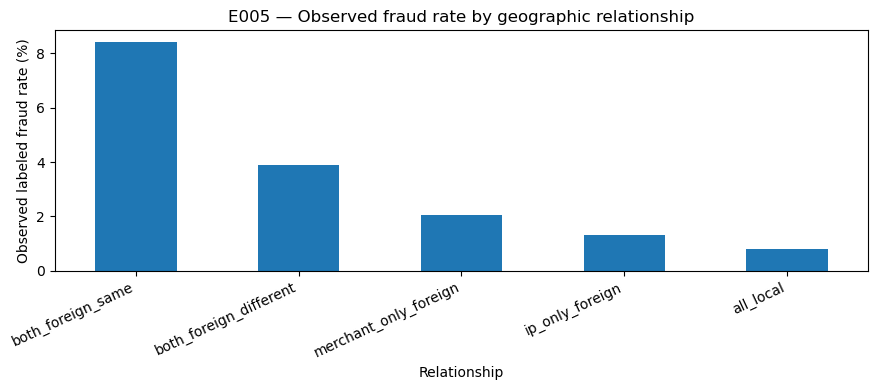

In [4]:
summary_rows = []
for feature_name in ALL_GEO_FEATURES:
    series = train_features[feature_name]
    if pd.api.types.is_numeric_dtype(series):
        summary_rows.append({
            "feature": feature_name,
            "unique_values": int(series.nunique()),
            "median": float(series.median()),
            "p95": float(series.quantile(.95)),
            "max": float(series.max()),
        })
    else:
        summary_rows.append({
            "feature": feature_name, "unique_values": int(series.nunique()),
            "median": None, "p95": None, "max": None,
        })
display(pd.DataFrame(summary_rows).round(3))

pattern_rates = (
    train_features.groupby("geo_country_pattern", observed=True)
    .agg(transactions=("is_fraud", "size"),
         frauds=("is_fraud", "sum"),
         observed_fraud_rate=("is_fraud", "mean"))
    .sort_values("observed_fraud_rate", ascending=False)
)
print("Fraud rates by IP/home/merchant relationship (EDA only):")
display(pattern_rates)

for feature in ["ip_country_changed_from_previous", "ip_country_change_within_1h"]:
    print("\n", feature)
    display(train_features.groupby(feature)["is_fraud"].agg(
        transactions="size", frauds="sum", observed_fraud_rate="mean"
    ))

fig, ax = plt.subplots(figsize=(9, 4))
pattern_rates["observed_fraud_rate"].mul(100).plot.bar(ax=ax)
ax.set(title="E005 — Observed fraud rate by geographic relationship",
       xlabel="Relationship", ylabel="Observed labeled fraud rate (%)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 5 — Feature sets and chronological validation folds

We use the **same 14 baseline features**, no E002/E003/E004 features, and the exact same validation dates:

| Fold | Training interval | Validation interval |
|---|---|---|
| 1 | Jan 1–18 | Jan 19–24, 2026 |
| 2 | Jan 1–24 | Jan 25–30, 2026 |
| 3 | Jan 1–30 | Jan 31–Feb 5, 2026 |

This makes the independent-group E005 scores comparable with earlier experiments. All `geo_country_pattern` values are categorical; other new features are numeric.

In [5]:
excluded_columns = {
    "transaction_id", "timestamp", "card_holder", "merchant_name",
    "ip_address", "is_fraud",
}
original_features = [
    column for column in train_raw.columns if column not in excluded_columns
]
assert len(original_features) == 14, original_features

feature_sets = {
    "E001-repeat": original_features,
    "E005-A": original_features + RELATIONSHIP_FEATURES,
    "E005-B": original_features + FAMILIARITY_FEATURES,
    "E005-C": original_features + SWITCH_FEATURES,
    "E005-D": original_features + ALL_GEO_FEATURES,
}
original_categorical_features = (
    train_raw[original_features]
    .select_dtypes(include=["object", "string", "category"])
    .columns.tolist()
)
time_folds = [
    ("2026-01-19", "2026-01-25"),
    ("2026-01-25", "2026-01-31"),
    ("2026-01-31", "2026-02-06"),
]
for experiment_id, columns in feature_sets.items():
    assert len(columns) == len(set(columns))
    assert set(columns).issubset(train_features.columns)
    print(f"{experiment_id:12s}: {len(columns)} features")

fold_checks = []
for fold_number, (start, end) in enumerate(time_folds, 1):
    start_date = pd.Timestamp(start)
    end_date = pd.Timestamp(end)
    train_mask = train_features["timestamp"] < start_date
    valid_mask = (
        train_features["timestamp"].ge(start_date) &
        train_features["timestamp"].lt(end_date)
    )
    y_fold_train = train_features.loc[train_mask, "is_fraud"]
    y_fold_valid = train_features.loc[valid_mask, "is_fraud"]
    assert y_fold_train.nunique() == 2 and y_fold_valid.nunique() == 2
    fold_checks.append({
        "fold": fold_number,
        "train_rows": len(y_fold_train),
        "train_frauds": int(y_fold_train.sum()),
        "valid_rows": len(y_fold_valid),
        "valid_frauds": int(y_fold_valid.sum()),
        "valid_start": start,
        "valid_end_exclusive": end,
    })
display(pd.DataFrame(fold_checks))

E001-repeat : 14 features
E005-A      : 16 features
E005-B      : 20 features
E005-C      : 18 features
E005-D      : 26 features


,fold,train_rows,train_frauds,valid_rows,valid_frauds,valid_start,valid_end_exclusive
0,1,29618,409,10336,140,2026-01-19,2026-01-25
1,2,39954,549,10263,94,2026-01-25,2026-01-31
2,3,50217,643,9980,156,2026-01-31,2026-02-06


## 6 — Train all E005 configurations on NVIDIA GPU

**GPU:** `task_type="GPU", devices="0"` targets your NVIDIA RTX 3070.

**Same CatBoost hyperparameters as E001–E004:** `iterations=600`, `depth=6`, `learning_rate=0.05`, `l2_leaf_reg=3`, `loss_function="Logloss"`, `eval_metric="AUC"`, and early stopping after 70 rounds.

Every experiment gets a **new model for each fold**. We compute the final validation ROC AUC using `sklearn.metrics.roc_auc_score()`.

A CatBoost message that AUC is not implemented *on GPU* relates to metric evaluation frequency; it does not mean tree training has switched to CPU.

**Research limitation:** These are model-selection scores because early stopping and feature-group selection both use the validation windows. We'll need an independent final check after choosing a configuration.

In [6]:
EXPERIMENTS_TO_RUN = [
    "E001-repeat", "E005-A", "E005-B", "E005-C", "E005-D"
]

model_parameters = dict(
    iterations=600,
    depth=6,
    learning_rate=0.05,
    l2_leaf_reg=3.0,
    loss_function="Logloss",
    eval_metric="AUC",
    task_type="GPU",
    devices="0",
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
)

results = []
importance_records = []
for experiment_id in EXPERIMENTS_TO_RUN:
    selected_columns = feature_sets[experiment_id]
    cat_features = (
        original_categorical_features + [
            feature for feature in GEO_CATEGORICAL_FEATURES
            if feature in selected_columns
        ]
    )
    print(f"\n===== {experiment_id}: {len(selected_columns)} features =====")

    for fold_number, (start, end) in enumerate(time_folds, 1):
        start_date, end_date = pd.Timestamp(start), pd.Timestamp(end)
        train_mask = train_features["timestamp"] < start_date
        valid_mask = (
            train_features["timestamp"].ge(start_date) &
            train_features["timestamp"].lt(end_date)
        )
        X_fold_train = train_features.loc[train_mask, selected_columns].copy()
        X_fold_valid = train_features.loc[valid_mask, selected_columns].copy()
        y_fold_train = train_features.loc[train_mask, "is_fraud"]
        y_fold_valid = train_features.loc[valid_mask, "is_fraud"]

        # Identical original categorical and boolean handling to E001.
        for frame in (X_fold_train, X_fold_valid):
            frame["card_present"] = frame["card_present"].astype("int8")
            frame[cat_features] = frame[cat_features].fillna("__MISSING__").astype(str)
        assert X_fold_train.columns.tolist() == X_fold_valid.columns.tolist()
        assert X_fold_train[cat_features].notna().all().all()
        assert X_fold_train.select_dtypes(include="number").notna().all().all()

        model = CatBoostClassifier(**model_parameters)
        started_at = perf_counter()
        model.fit(
            X_fold_train, y_fold_train,
            cat_features=cat_features,
            eval_set=(X_fold_valid, y_fold_valid),
            early_stopping_rounds=70,
            use_best_model=True,
        )
        seconds = perf_counter() - started_at
        probabilities = model.predict_proba(X_fold_valid)[:, 1]
        fold_auc = roc_auc_score(y_fold_valid, probabilities)
        results.append({
            "experiment_id": experiment_id,
            "fold": fold_number,
            "train_rows": len(X_fold_train),
            "valid_rows": len(X_fold_valid),
            "valid_frauds": int(y_fold_valid.sum()),
            "roc_auc": fold_auc,
            "best_iteration": model.best_iteration_,
            "train_seconds": round(seconds, 2),
        })
        for feature_name, importance in zip(
            selected_columns, model.get_feature_importance()
        ):
            importance_records.append({
                "experiment_id": experiment_id,
                "fold": fold_number,
                "feature": feature_name,
                "importance": float(importance),
            })
        print(
            f"Fold {fold_number}: AUC={fold_auc:.5f}, "
            f"best_iteration={model.best_iteration_}, "
            f"seconds={seconds:.1f}"
        )

results_df = pd.DataFrame(results)
importance_df = pd.DataFrame(importance_records)
display(results_df)


===== E001-repeat: 14 features =====


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 1: AUC=0.88680, best_iteration=90, seconds=9.5


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 2: AUC=0.83746, best_iteration=16, seconds=5.1


Default metric period is 5 because AUC is/are not implemented for GPU


... (22 outputs left out)

Fold 2: AUC=0.86073, best_iteration=16, seconds=5.4


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 3: AUC=0.91505, best_iteration=15, seconds=2.9


,experiment_id,fold,train_rows,valid_rows,valid_frauds,roc_auc,best_iteration,train_seconds
0,E001-repeat,1,29618,10336,140,0.886804,90,9.51
1,E001-repeat,2,39954,10263,94,0.837461,16,5.11
2,E001-repeat,3,50217,9980,156,0.898440,14,2.68
3,E005-A,1,29618,10336,140,0.886650,90,9.42
4,E005-A,2,39954,10263,94,0.855852,460,29.29
5,E005-A,3,50217,9980,156,0.894669,15,2.79
6,E005-B,1,29618,10336,140,0.886582,416,27.07
7,E005-B,2,39954,10263,94,0.855230,347,24.03
8,E005-B,3,50217,9980,156,0.892936,14,2.71
9,E005-C,1,29618,10336,140,0.897674,93,9.44


## 7 — Evaluate mean AUC, variation, and paired fold improvements

Which geography group has the highest **mean ROC AUC**? Does it improve all three folds? Does combining all E005 features help or hurt? We use the freshly rerun **E001-repeat** control for `delta_vs_e001`, not an old score copied from a prior notebook.

AUC summary:


,experiment_id,mean_roc_auc,std_roc_auc,min_fold_auc,max_fold_auc,mean_best_iteration,delta_vs_e001
0,E001-repeat,0.87424,0.03237,0.83746,0.89844,40.00000,0.00000
1,E005-A,0.87906,0.02049,0.85585,0.89467,188.33333,0.00482
2,E005-B,0.87825,0.02019,0.85523,0.89294,259.00000,0.00401
3,E005-C,0.89657,0.02627,0.86976,0.92226,232.66667,0.02233
4,E005-D,0.88734,0.02718,0.86073,0.91505,28.33333,0.01311


ROC AUC by fold:


experiment_id,E001-repeat,E005-A,E005-B,E005-C,E005-D
fold,,,,,
1,0.88680,0.88665,0.88658,0.89767,0.88624
2,0.83746,0.85585,0.85523,0.86976,0.86073
3,0.89844,0.89467,0.89294,0.92226,0.91505


Paired fold improvement relative to E001-repeat:


experiment_id,E001-repeat,E005-A,E005-B,E005-C,E005-D
fold,,,,,
1,0.0,-0.00015,-0.00022,0.01087,-0.00057
2,0.0,0.01839,0.01777,0.03230,0.02327
3,0.0,-0.00377,-0.00550,0.02382,0.01661


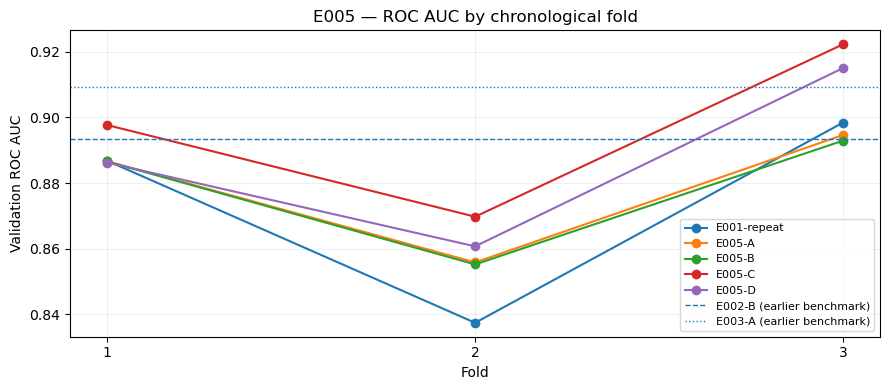

In [7]:
summary_df = (
    results_df.groupby("experiment_id", sort=False)
    .agg(
        mean_roc_auc=("roc_auc", "mean"),
        std_roc_auc=("roc_auc", "std"),
        min_fold_auc=("roc_auc", "min"),
        max_fold_auc=("roc_auc", "max"),
        mean_best_iteration=("best_iteration", "mean"),
    )
    .reset_index()
)
baseline_auc = float(
    summary_df.loc[
        summary_df["experiment_id"] == "E001-repeat", "mean_roc_auc"
    ].iloc[0]
)
summary_df["delta_vs_e001"] = summary_df["mean_roc_auc"] - baseline_auc
print("AUC summary:")
display(summary_df.round(5))

fold_table = results_df.pivot(
    index="fold", columns="experiment_id", values="roc_auc"
)
print("ROC AUC by fold:")
display(fold_table.round(5))
print("Paired fold improvement relative to E001-repeat:")
display(fold_table.subtract(fold_table["E001-repeat"], axis=0).round(5))

fig, ax = plt.subplots(figsize=(9, 4))
for experiment_id in fold_table.columns:
    ax.plot(fold_table.index, fold_table[experiment_id],
            marker="o", label=experiment_id)
ax.axhline(0.89328, linewidth=1, linestyle="--",
           label="E002-B (earlier benchmark)")
ax.axhline(0.90917, linewidth=1, linestyle=":",
           label="E003-A (earlier benchmark)")
ax.set(title="E005 — ROC AUC by chronological fold",
       xlabel="Fold", ylabel="Validation ROC AUC", xticks=[1, 2, 3])
ax.legend(loc="best", fontsize=8)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 8 — Feature importance across the three folds

Importance measures how CatBoost used each feature in its fitted model; it is **not** proof of a feature's causal effect, nor proof that removing low-importance features will improve generalization. Inspect average importance across all folds and compare it with AUC changes.

In [8]:
for experiment_id in ["E005-A", "E005-B", "E005-C", "E005-D"]:
    subset = importance_df.loc[importance_df["experiment_id"] == experiment_id]
    importance_summary = (
        subset.groupby("feature", as_index=False)
        .agg(
            mean_importance=("importance", "mean"),
            min_importance=("importance", "min"),
            max_importance=("importance", "max"),
        )
        .sort_values("mean_importance", ascending=False)
    )
    print(f"\n{experiment_id} — Mean importance across three folds")
    display(importance_summary.head(26).round(3))


E005-A — Mean importance across three folds


,feature,mean_importance,min_importance,max_importance
1,amount,28.801,13.197,39.306
13,merchant_category,21.288,14.449,33.403
15,merchant_id,15.531,14.150,16.483
8,geo_country_pattern,7.716,7.304,8.482
12,is_foreign_merchant,6.724,3.844,10.991
2,card_id,6.027,1.219,8.586
0,account_age_days,3.177,1.926,4.607
4,channel,2.983,1.203,5.133
6,customer_home_country,1.646,1.301,2.151
14,merchant_country,1.482,0.830,2.471



E005-B — Mean importance across three folds


,feature,mean_importance,min_importance,max_importance
1,amount,24.655,12.638,31.629
17,merchant_category,15.402,14.451,17.062
19,merchant_id,15.197,12.135,20.109
16,is_foreign_merchant,6.812,3.083,13.441
5,card_merchant_country_share,5.829,4.234,7.732
10,channel,5.314,2.314,10.614
2,card_id,4.826,0.000,7.484
0,account_age_days,3.845,3.674,4.152
3,card_ip_country_share,2.961,2.549,3.205
6,card_merchant_country_txn_count,2.846,2.190,3.193



E005-C — Mean importance across three folds


,feature,mean_importance,min_importance,max_importance
1,amount,26.593,13.128,36.390
13,merchant_category,25.505,17.828,37.506
17,merchant_id,12.665,11.835,13.280
12,is_foreign_merchant,12.474,6.679,21.734
2,card_id,5.389,0.000,8.566
4,channel,2.835,2.584,3.109
0,account_age_days,2.635,0.803,5.556
11,is_foreign_ip,2.419,1.300,3.097
9,ip_country_change_within_1h,2.129,1.314,3.467
14,merchant_country,1.990,1.114,3.689



E005-D — Mean importance across three folds


,feature,mean_importance,min_importance,max_importance
1,amount,22.112,11.401,42.218
25,merchant_id,20.655,14.077,30.270
21,merchant_category,20.519,15.285,29.998
14,geo_country_pattern,6.918,5.294,7.770
20,is_foreign_merchant,6.871,1.904,11.959
16,ip_country_change_within_1h,4.275,1.370,5.847
2,card_id,2.774,0.000,8.323
5,card_merchant_country_share,2.640,1.113,4.191
3,card_ip_country_share,2.199,0.934,2.882
6,card_merchant_country_txn_count,2.040,1.627,2.442


## 9 — Save results to `experiments/`

The notebook writes three CSVs, matching the previous experiment's reporting structure. You can commit the notebook and outputs to Git once you've reviewed them.

In [9]:
experiments_dir = project_root / "experiments"
experiments_dir.mkdir(parents=True, exist_ok=True)

results_path = experiments_dir / "E005_cv_results.csv"
summary_path = experiments_dir / "E005_summary.csv"
importance_path = experiments_dir / "E005_feature_importance.csv"

results_df.to_csv(results_path, index=False)
summary_df.to_csv(summary_path, index=False)
importance_df.to_csv(importance_path, index=False)
print("Saved:", results_path)
print("Saved:", summary_path)
print("Saved:", importance_path)

Saved: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost\experiments\E005_cv_results.csv
Saved: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost\experiments\E005_summary.csv
Saved: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost\experiments\E005_feature_importance.csv


## 10 — Conclusion (fill in after GPU training)

| Configuration | Mean ROC AUC | Δ vs E001 | Fold behavior | Decision |
|---|---:|---:|---|---|
| E001-repeat | _pending_ | 0 | Reference | Control |
| E005-A — relationships | _pending_ | _pending_ | _pending_ | _pending_ |
| E005-B — familiarity | _pending_ | _pending_ | _pending_ | _pending_ |
| E005-C — country switches | _pending_ | _pending_ | _pending_ | _pending_ |
| E005-D — all geography | _pending_ | _pending_ | _pending_ | _pending_ |

**Checkpoints:**

1. Which new geographic feature group improves ROC AUC most, and does it improve all three folds?
2. Does explicit geographic interaction add information beyond the original `is_foreign_ip` / `is_foreign_merchant` flags?
3. Are card-country frequencies helpful, or are they noisy due to the short transaction-history window?
4. Do country-change features offer more than card-level velocity alone (E003)? We'll test overlap in E006.
5. Does the full E005-D configuration beat the best single E005 group?

**Decision principle:** Select candidates based on paired chronological validation performance, not raw feature importance alone. We have explored many groups on the same three windows, so observed gains can be optimistic. Before claiming a final winner, perform an independent later-period evaluation if possible.

**Next:** **E006 — Cross-group feature combination**, testing the strongest E002 spending, E003 velocity, E004 card–merchant familiarity, and E005 geographic features together.